# DSCI 552 HW 6 - Jazmine Tabora

## 1. Tree-Based Methods

### (a) Download Data

### (b) Data Preparation
This data set has missing values. When the number of data with missing values is significant, discarding them is not a good idea.

#### (i) Research what types of techniques are usually used for dealing with data with missing values.2 Pick at least one of them and apply it to this data in the next steps.

#### ANSWER
The methods I found for dealing with data that is missing values is either deleting the rows or features and replacing the missing values with summary statistics or by using KNN or iterative imputation.

#### (ii) For each of the 170 features, calculate the coefficient of variation CV = s/m, where s is sample standard deviation and m is sample mean

In [1]:
import pandas as pd

In [2]:
# Training data
train_df = pd.read_csv(
    "aps_failure_training_set.csv",
    skiprows=20,  # skipping the file's copyright and description text
    na_values="na"  # missing value marker
)

X = train_df.drop(columns="class")

X_imputed = X.fillna(X.median())  # replacing missing values w/ median

feature_means = X_imputed.mean()   # mean
feature_sds = X_imputed.std()  # standard deviation

# Calculating CV = s/m
cv = feature_sds / feature_means

# Table of results
cv_table = pd.DataFrame({
    "mean": feature_means,
    "sample_sd": feature_sds,
    "CV": cv
}).sort_values("CV", ascending=False)

cv_table

,mean,sample_sd,CV
cf_000,1.431075e+05,3.504525e+07,244.887517
co_000,1.433300e+05,3.504525e+07,244.507385
ad_000,1.434383e+05,3.504525e+07,244.322816
cs_009,7.705097e+02,1.833278e+05,237.930554
dh_000,4.392641e+03,5.412441e+05,123.216097
...,...,...,...
bo_000,3.258947e+05,2.582334e+05,0.792383
bp_000,3.420739e+05,2.577156e+05,0.753392
bq_000,3.573117e+05,2.567407e+05,0.718534
br_000,3.713041e+05,2.558701e+05,0.689112


#### (iii) Plot a correlation matrix for your features using pandas or any other tool

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

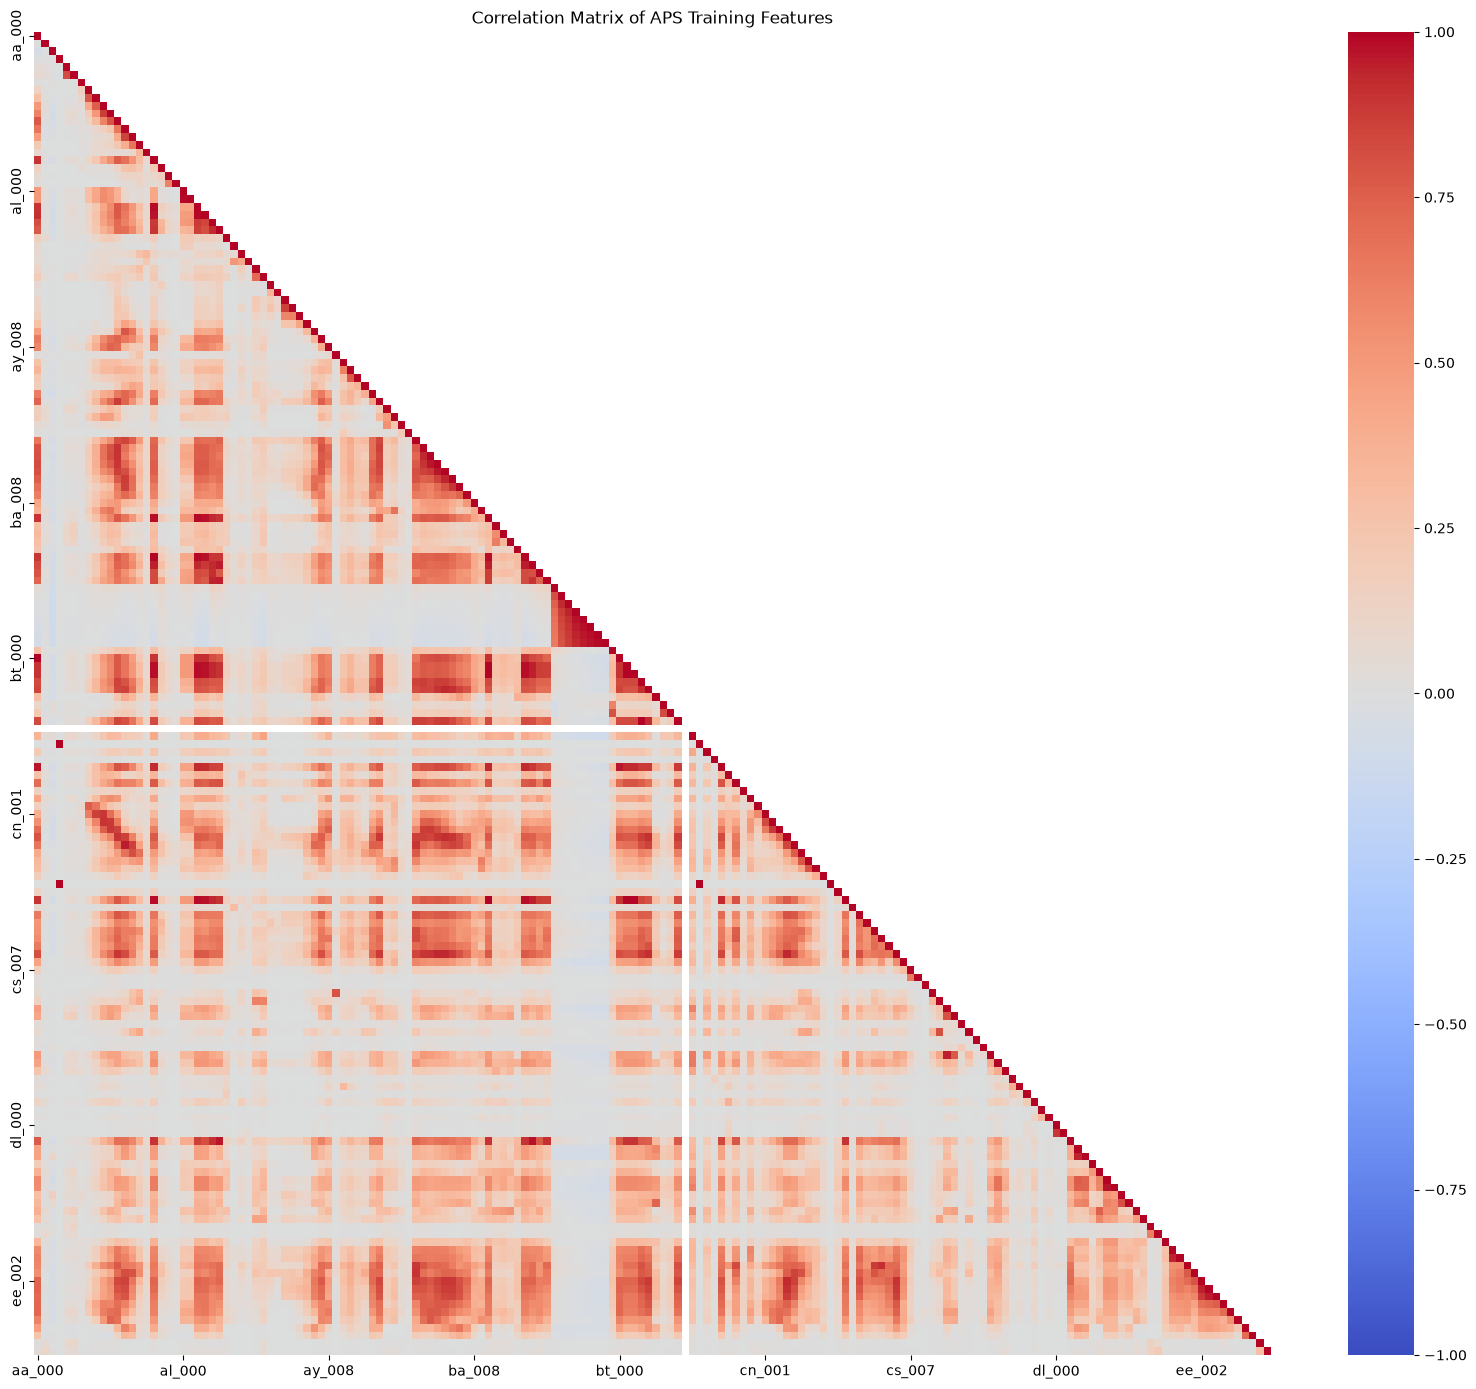

In [4]:
correlation_matrix = X_imputed.corr()

# Show each pair only once
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool), k=1)

plt.figure(figsize=(16, 14))
sns.heatmap(
    correlation_matrix,
    mask=mask,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=20,
    yticklabels=20
)

plt.title("Correlation Matrix of APS Training Features")
plt.tight_layout()
plt.show()

#### (iv) Pick √170 features with highest CV , and make scatter plots and box plots for them, similar to those on p. 129 of ISLR. Can you draw conclusions about significance of those features, just by the scatter plots? This does not mean that you will only use those features in the following questions. We picked them only for visualization

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


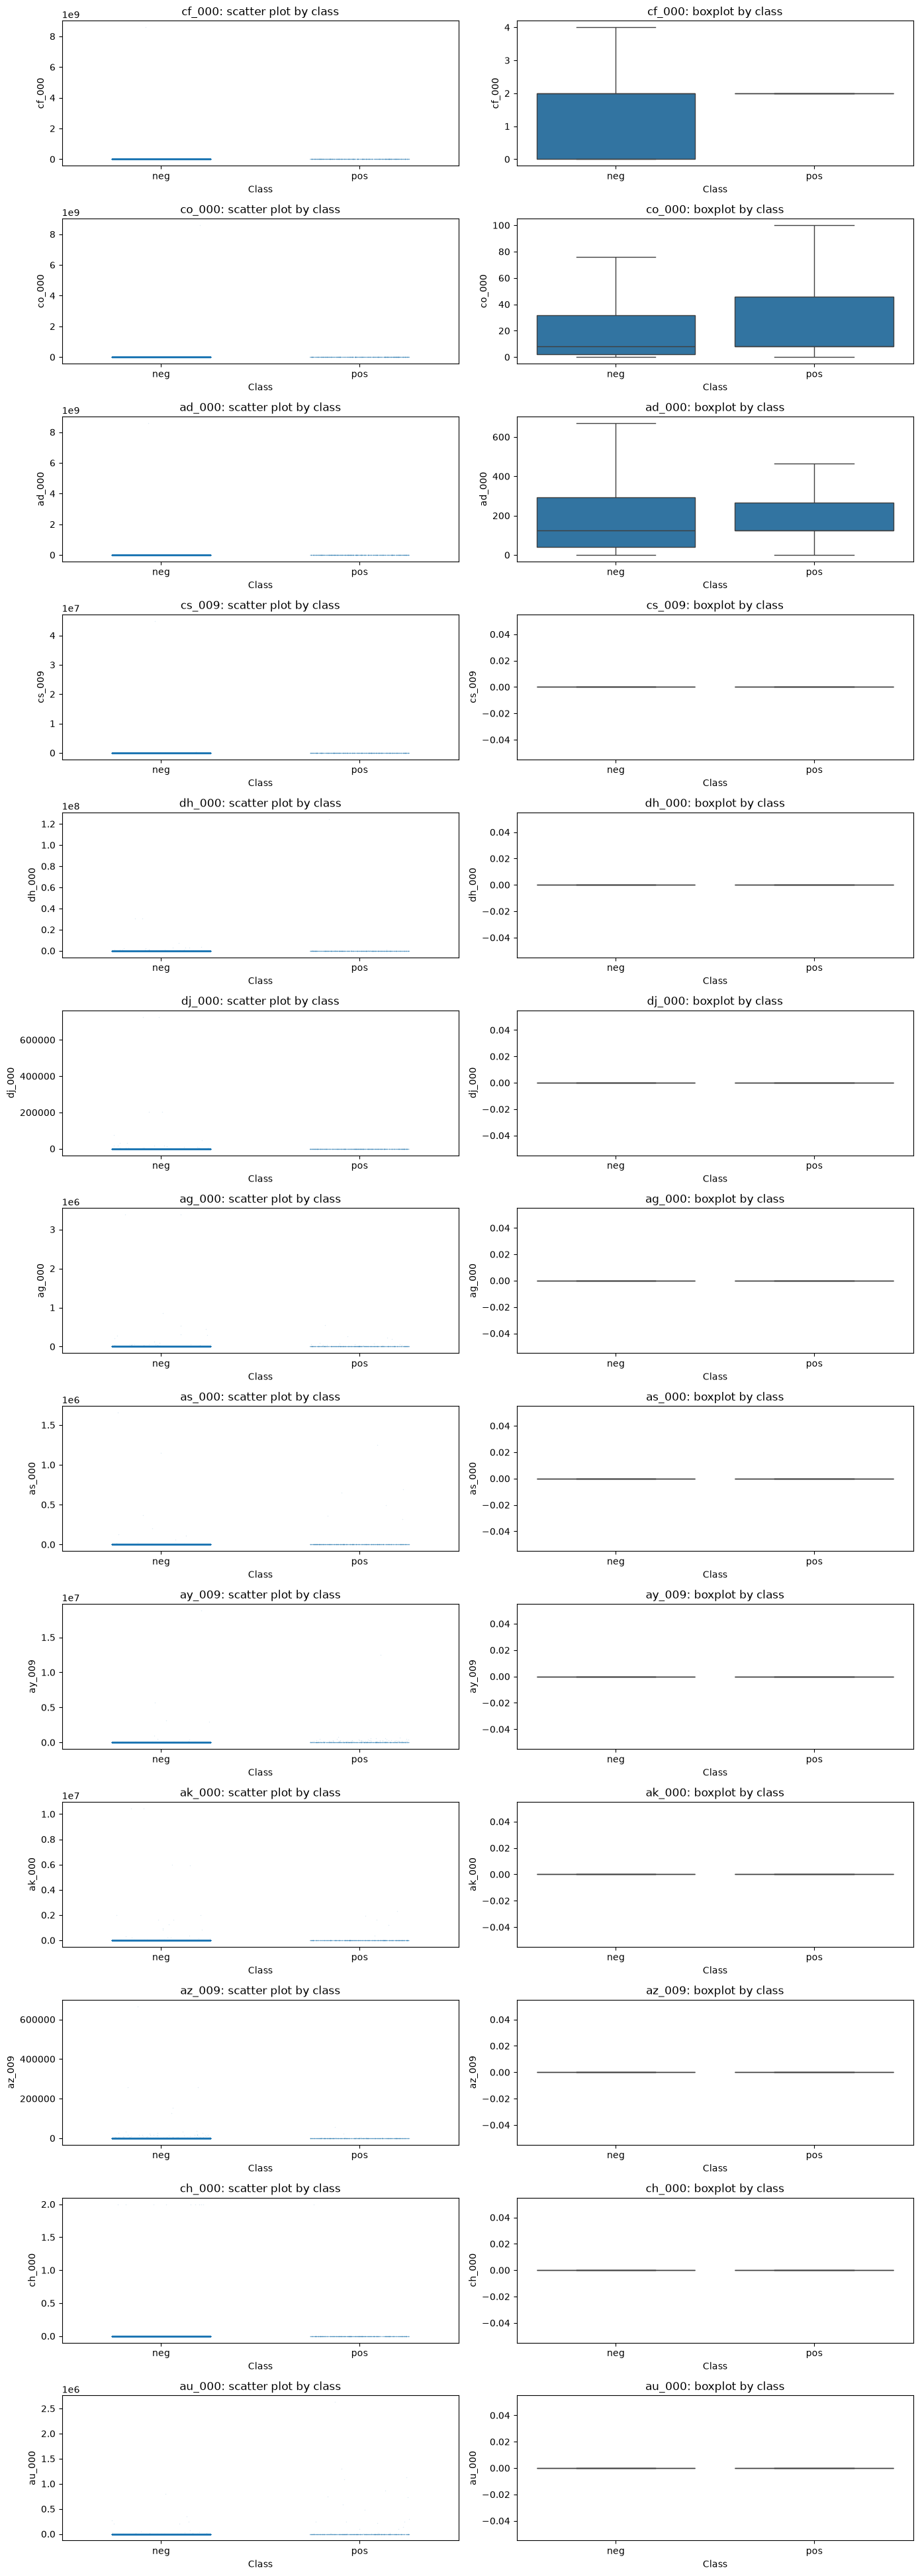

In [7]:
# The square root of 170 is about 13, so 13 feature names with the largest CV values
top_features = cv.nlargest(13).index.tolist()
print(top_features)

plot_data = X_imputed[top_features].copy()
plot_data["class"] = train_df["class"]

class_order = ["neg", "pos"]

fig, axes = plt.subplots(
    nrows=len(top_features),
    ncols=2,
    figsize=(14, 3 * len(top_features))
)

for i, feature in enumerate(top_features):
    sns.stripplot(
        data=plot_data,
        x="class",
        y=feature,
        order=class_order,
        jitter=0.25,  # separates overlapping points
        alpha=0.15,
        size=1,
        ax=axes[i, 0]
    )
    axes[i, 0].set_title(f"{feature}: scatter plot by class")
    axes[i, 0].set_xlabel("Class")
    axes[i, 0].set_ylabel(feature)

    sns.boxplot(
        data=plot_data,
        x="class",
        y=feature,
        order=class_order,
        showfliers=False,
        ax=axes[i, 1]
    )
    axes[i, 1].set_title(f"{feature}: boxplot by class")
    axes[i, 1].set_xlabel("Class")
    axes[i, 1].set_ylabel(feature)

plt.tight_layout()
plt.show()

##### ANSWER
The plots aren't great and just from looking at the visual difference between the two classes I can't establish statistical significance. 

#### (v) Determine the number of positive and negative data. Is this data set imbalanced?


In [9]:
class_summary = pd.DataFrame({
    "count": train_df["class"].value_counts(),
    "percentage": train_df["class"].value_counts(normalize=True) * 100
})

class_summary

,count,percentage
class,,
neg,59000,98.333333
pos,1000,1.666667


#### ANSWER
The data set is highly imbalanced. There are 59 negative examples for every one positive example.

### (c)  Train a random forest to classify the data set. Do NOT compensate for class imbalance in the data set. Calculate the confusion matrix, ROC, AUC, and misclassification for training and test sets and report them (You may use pROC package). Calculate Out of Bag error estimate for your random forset and compare it to the test error.

In [10]:
# Test data
test_df = pd.read_csv(
    "aps_failure_test_set.csv",
    skiprows=20,
    na_values="na"
)

X_train = X_imputed
X_test_raw = test_df[X.columns]
X_test_imputed = X_test_raw.fillna(X.median())

y_train = train_df["class"]
y_test = test_df["class"]

print("Training features:", X_train.shape)
print("Test features:", X_test_imputed.shape)
print("\nTraining classes:\n", y_train.value_counts())
print("\nTest classes:\n", y_test.value_counts())

Training features: (60000, 170)
Test features: (16000, 170)

Training classes:
 class
neg    59000
pos     1000
Name: count, dtype: int64

Test classes:
 class
neg    15625
pos      375
Name: count, dtype: int64


In [11]:
from sklearn.ensemble import RandomForestClassifier

In [12]:
rf = RandomForestClassifier(
    n_estimators=100,
    max_features="sqrt",
    class_weight=None,  # do not compensate for class imbalance
    oob_score=True,
    n_jobs=-1,
    random_state=42
)

rf.fit(X_train, y_train)

oob_accuracy = rf.oob_score_
oob_error = 1 - oob_accuracy

print("OOB accuracy:", oob_accuracy)
print("OOB error:", oob_error)

OOB accuracy: 0.9938333333333333
OOB error: 0.006166666666666654


In [14]:
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

In [15]:
# Class predictions
y_train_pred = rf.predict(X_train)
y_test_pred = rf.predict(X_test_imputed)

pos_column = list(rf.classes_).index("pos")
train_pos_prob = rf.predict_proba(X_train)[:, pos_column]
test_pos_prob = rf.predict_proba(X_test_imputed)[:, pos_column]

train_cm = confusion_matrix(y_train, y_train_pred, labels=["neg", "pos"])
test_cm = confusion_matrix(y_test, y_test_pred, labels=["neg", "pos"])

print("Training confusion matrix:")
display(pd.DataFrame(
    train_cm,
    index=["Actual neg", "Actual pos"],
    columns=["Predicted neg", "Predicted pos"]
))

print("Test confusion matrix:")
display(pd.DataFrame(
    test_cm,
    index=["Actual neg", "Actual pos"],
    columns=["Predicted neg", "Predicted pos"]
))

Training confusion matrix:


,Predicted neg,Predicted pos
Actual neg,59000,0
Actual pos,1,999


Test confusion matrix:


,Predicted neg,Predicted pos
Actual neg,15610,15
Actual pos,106,269


Training misclassification rate: 0.0000
Test misclassification rate: 0.0076
Training AUC: 1.0000
Test AUC: 0.9927


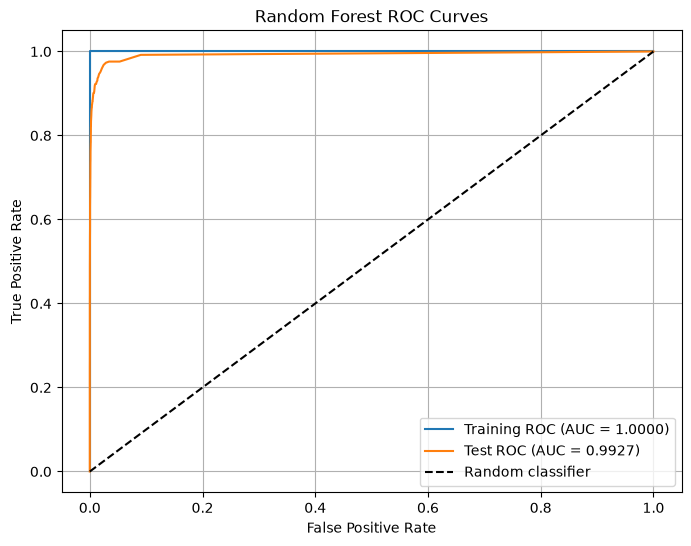

In [16]:
# Misclassification rate = number of incorrect predictions / total predictions
train_error = np.mean(y_train_pred != y_train)
test_error = np.mean(y_test_pred != y_test)

# ROC curves and AUC
train_fpr, train_tpr, _ = roc_curve(y_train, train_pos_prob, pos_label="pos")
test_fpr, test_tpr, _ = roc_curve(y_test, test_pos_prob, pos_label="pos")

train_auc = roc_auc_score(y_train == "pos", train_pos_prob)
test_auc = roc_auc_score(y_test == "pos", test_pos_prob)

print(f"Training misclassification rate: {train_error:.4f}")
print(f"Test misclassification rate: {test_error:.4f}")
print(f"Training AUC: {train_auc:.4f}")
print(f"Test AUC: {test_auc:.4f}")

plt.figure(figsize=(8, 6))
plt.plot(train_fpr, train_tpr, label=f"Training ROC (AUC = {train_auc:.4f})")
plt.plot(test_fpr, test_tpr, label=f"Test ROC (AUC = {test_auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curves")
plt.legend()
plt.grid(True)
plt.show()

### (d) Research how class imbalance is addressed in random forests. Compensate for class imbalance in your random forest and repeat 1c. Compare the results with those of 1c.

#### Answer
A common way to address class imbalance is to assign higher weights to observations from the minority class. In Scikit-learn I can use class_weight="balanced" to inversely calculate the class weights to their frequencies.

In [17]:
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    max_features="sqrt",
    class_weight="balanced",
    oob_score=True,
    n_jobs=-1,
    random_state=42
)

rf_balanced.fit(X_train, y_train)

oob_accuracy_balanced = rf_balanced.oob_score_
oob_error_balanced = 1 - oob_accuracy_balanced

print("Balanced RF OOB accuracy:", oob_accuracy_balanced)
print("Balanced RF OOB error:", oob_error_balanced)

Balanced RF OOB accuracy: 0.9797833333333333
Balanced RF OOB error: 0.02021666666666666


c:\Users\tabor\.anaconda-desktop\micromamba\envs\cpu\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


In [18]:
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

In [19]:
y_train_pred_balanced = rf_balanced.predict(X_train)
y_test_pred_balanced = rf_balanced.predict(X_test_imputed)

pos_column_balanced = list(rf_balanced.classes_).index("pos")
train_pos_prob_balanced = rf_balanced.predict_proba(X_train)[:, pos_column_balanced]
test_pos_prob_balanced = rf_balanced.predict_proba(X_test_imputed)[:, pos_column_balanced]

train_cm_balanced = confusion_matrix(
    y_train, y_train_pred_balanced, labels=["neg", "pos"]
)
test_cm_balanced = confusion_matrix(
    y_test, y_test_pred_balanced, labels=["neg", "pos"]
)

print("Balanced RF training confusion matrix:")
display(pd.DataFrame(
    train_cm_balanced,
    index=["Actual neg", "Actual pos"],
    columns=["Predicted neg", "Predicted pos"]
))

print("Balanced RF test confusion matrix:")
display(pd.DataFrame(
    test_cm_balanced,
    index=["Actual neg", "Actual pos"],
    columns=["Predicted neg", "Predicted pos"]
))

Balanced RF training confusion matrix:


,Predicted neg,Predicted pos
Actual neg,58986,14
Actual pos,0,1000


Balanced RF test confusion matrix:


,Predicted neg,Predicted pos
Actual neg,15571,54
Actual pos,99,276


Balanced RF training misclassification rate: 0.0002
Balanced RF test misclassification rate: 0.0096
Balanced RF training AUC: 1.0000
Balanced RF test AUC: 0.9944


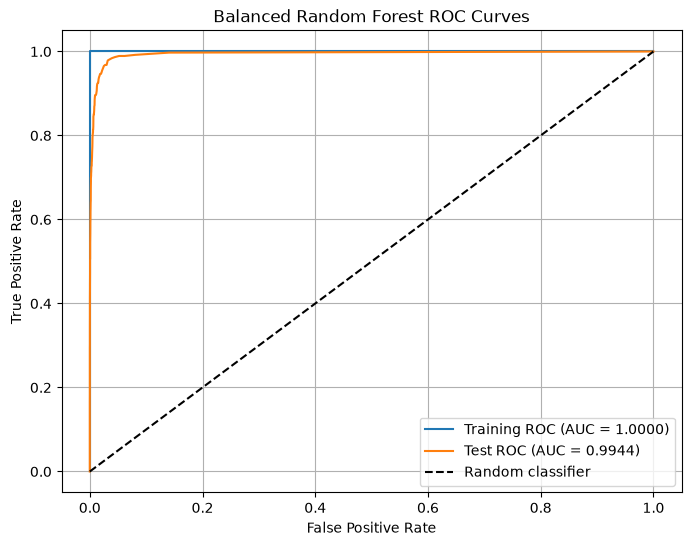

In [20]:
train_error_balanced = (y_train_pred_balanced != y_train).mean()
test_error_balanced = (y_test_pred_balanced != y_test).mean()

# ROC curves and AUC
train_fpr_balanced, train_tpr_balanced, _ = roc_curve(
    y_train, train_pos_prob_balanced, pos_label="pos"
)
test_fpr_balanced, test_tpr_balanced, _ = roc_curve(
    y_test, test_pos_prob_balanced, pos_label="pos"
)

train_auc_balanced = roc_auc_score(
    y_train == "pos", train_pos_prob_balanced
)
test_auc_balanced = roc_auc_score(
    y_test == "pos", test_pos_prob_balanced
)

print(f"Balanced RF training misclassification rate: {train_error_balanced:.4f}")
print(f"Balanced RF test misclassification rate: {test_error_balanced:.4f}")
print(f"Balanced RF training AUC: {train_auc_balanced:.4f}")
print(f"Balanced RF test AUC: {test_auc_balanced:.4f}")

plt.figure(figsize=(8, 6))
plt.plot(
    train_fpr_balanced, train_tpr_balanced,
    label=f"Training ROC (AUC = {train_auc_balanced:.4f})"
)
plt.plot(
    test_fpr_balanced, test_tpr_balanced,
    label=f"Test ROC (AUC = {test_auc_balanced:.4f})"
)
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Balanced Random Forest ROC Curves")
plt.legend()
plt.grid(True)
plt.show()

#### ANSWER
The inverse-frequency class weights were slightly better than the random forest's detection of positive cases. However, the balanced model also had more false positives and its test misclassification was higher. 

### (e) XGBoost and Model Trees

In [21]:
import xgboost as xgb
print(xgb.__version__)

3.4.1


In [22]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

In [23]:
y_train_binary = (y_train == "pos").astype(int)

five_fold_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

xgb_model = XGBClassifier(
    objective="binary:logistic",
    booster="gbtree",
    eval_metric="logloss",
    tree_method="hist",
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    reg_lambda=1,
    random_state=42,
    n_jobs=1
)

alpha_grid = {
    "reg_alpha": [0, 0.01, 0.1, 1, 10]
}

xgb_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=alpha_grid,
    scoring={"roc_auc": "roc_auc", "accuracy": "accuracy"},
    refit="roc_auc",
    cv=five_fold_cv,
    n_jobs=-1,
    verbose=2
)

xgb_search.fit(X_train, y_train_binary)

best_index = xgb_search.best_index_
cv_accuracy = xgb_search.cv_results_["mean_test_accuracy"][best_index]
cv_error = 1 - cv_accuracy

print("Best alpha:", xgb_search.best_params_["reg_alpha"])
print("Best 5-fold CV ROC AUC:", xgb_search.best_score_)
print("5-fold CV accuracy at best alpha:", cv_accuracy)
print("5-fold CV misclassification rate:", cv_error)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best alpha: 0.01
Best 5-fold CV ROC AUC: 0.9897888559322034
5-fold CV accuracy at best alpha: 0.9942333333333334
5-fold CV misclassification rate: 0.005766666666666587


### (f) Use SMOTE (Synthetic Minority Over-sampling Technique) to pre-process your data to compensate for class imbalance.4 Train XGBosst with L1-penalized logistic regression at each node using the pre-processed data and repeat 1e. Do not forget that there is a right and a wrong way of cross validation here. Compare the uncompensated case with SMOTE case

In [24]:
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

In [25]:
xgb_best = xgb_search.best_estimator_

y_test_binary = (y_test == "pos").astype(int)

y_train_pred_xgb = xgb_best.predict(X_train)
y_test_pred_xgb = xgb_best.predict(X_test_imputed)

train_prob_xgb = xgb_best.predict_proba(X_train)[:, 1]
test_prob_xgb = xgb_best.predict_proba(X_test_imputed)[:, 1]

train_cm_xgb = confusion_matrix(
    y_train_binary, y_train_pred_xgb, labels=[0, 1]
)
test_cm_xgb = confusion_matrix(
    y_test_binary, y_test_pred_xgb, labels=[0, 1]
)

print("XGBoost training confusion matrix:")
display(pd.DataFrame(
    train_cm_xgb,
    index=["Actual neg", "Actual pos"],
    columns=["Predicted neg", "Predicted pos"]
))

print("XGBoost test confusion matrix:")
display(pd.DataFrame(
    test_cm_xgb,
    index=["Actual neg", "Actual pos"],
    columns=["Predicted neg", "Predicted pos"]
))

XGBoost training confusion matrix:


,Predicted neg,Predicted pos
Actual neg,58999,1
Actual pos,33,967


XGBoost test confusion matrix:


,Predicted neg,Predicted pos
Actual neg,15611,14
Actual pos,89,286


XGBoost training misclassification rate: 0.0006
XGBoost test misclassification rate: 0.0064
XGBoost training AUC: 0.9999
XGBoost test AUC: 0.9954


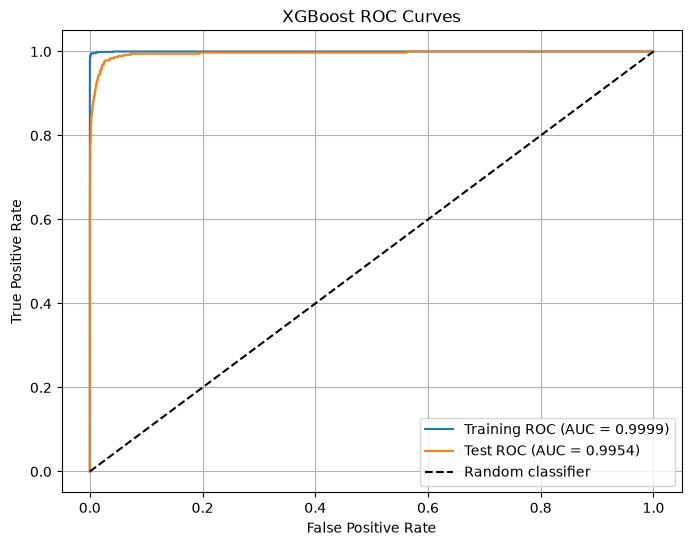

In [26]:
train_error_xgb = (y_train_pred_xgb != y_train_binary).mean()
test_error_xgb = (y_test_pred_xgb != y_test_binary).mean()

# ROC curves and AUC
train_fpr_xgb, train_tpr_xgb, _ = roc_curve(
    y_train_binary, train_prob_xgb
)
test_fpr_xgb, test_tpr_xgb, _ = roc_curve(
    y_test_binary, test_prob_xgb
)

train_auc_xgb = roc_auc_score(y_train_binary, train_prob_xgb)
test_auc_xgb = roc_auc_score(y_test_binary, test_prob_xgb)

print(f"XGBoost training misclassification rate: {train_error_xgb:.4f}")
print(f"XGBoost test misclassification rate: {test_error_xgb:.4f}")
print(f"XGBoost training AUC: {train_auc_xgb:.4f}")
print(f"XGBoost test AUC: {test_auc_xgb:.4f}")

# Plot training and test ROC curves
plt.figure(figsize=(8, 6))
plt.plot(train_fpr_xgb, train_tpr_xgb, label=f"Training ROC (AUC = {train_auc_xgb:.4f})")
plt.plot(test_fpr_xgb, test_tpr_xgb, label=f"Test ROC (AUC = {test_auc_xgb:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curves")
plt.legend()
plt.grid(True)
plt.show()

## 2. ISLR 6.6.3

##### ANSWER
* (a) steadily decreases
* (b) decreases and then increases
* (c) steadily increases
* (d) steadily decreases
* (e) constant

## 4. ISLR 8.4.5

#### ANSWER
The majority vote would predict Red and the average probabily is 0.45 so it would predict Green.

## 5. ISLR 9.7.3

(a) I plotted the four Red observations at (3,4),(2,2),(4,4),(1,4) and the three Blue observations at (2,1),(4,3),(4,1)

(b) The maximal-margin hyperplane is $1-2X_1+2X_2=0$ or $X_2=X_1-0.5$

(c) Red if $1-2X_1+2X_2>0$ and Blue otherwise. Therefore $\beta_0=1$ $\beta_1=-2$ and $\beta_2=2$

(d) The two margin boundaries are $X_2=X_1$ and $X_2=X_1-1$. The maximal margin hyperplane is between them

(e) The support vectors are observations 2, 3, 5, and 6.

(f) Observation 7 is not a support vector. It will not change the maximal margin hyperplane as long as it is outside the margin